<a href="https://colab.research.google.com/github/Azhar-TKM/AI-ML/blob/main/MSE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

df = pd.read_csv('/content/student_performance_dataset.csv')
df.describe()


,student_id,study_time_hours,attendance_percent,sleep_hours,previous_grade,final_exam_score
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,500.500000,3.570700,85.092300,6.799500,69.740900,83.543500
std,288.819436,1.478559,9.270685,1.203527,12.613425,10.341333
min,1.000000,0.500000,54.800000,3.200000,31.300000,46.800000
25%,250.750000,2.600000,78.800000,5.900000,61.000000,76.075000
50%,500.500000,3.600000,85.200000,6.800000,69.600000,83.800000
75%,750.250000,4.500000,91.900000,7.600000,78.400000,91.525000
max,1000.000000,8.100000,100.000000,10.000000,100.000000,100.000000


In [ ]:
X = df[['study_time_hours', 'attendance_percent', 'sleep_hours', 'previous_grade']]
y = df['final_exam_score']

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
comparison = pd.DataFrame({
    'Actual': y_test,
    'Predicted': y_pred
})
comparison.head()

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f'Mean Squared Error: {mse:.2f}')
print(f'R-squared: {r2:.2f}')


Mean Squared Error: 41.48
R-squared: 0.61


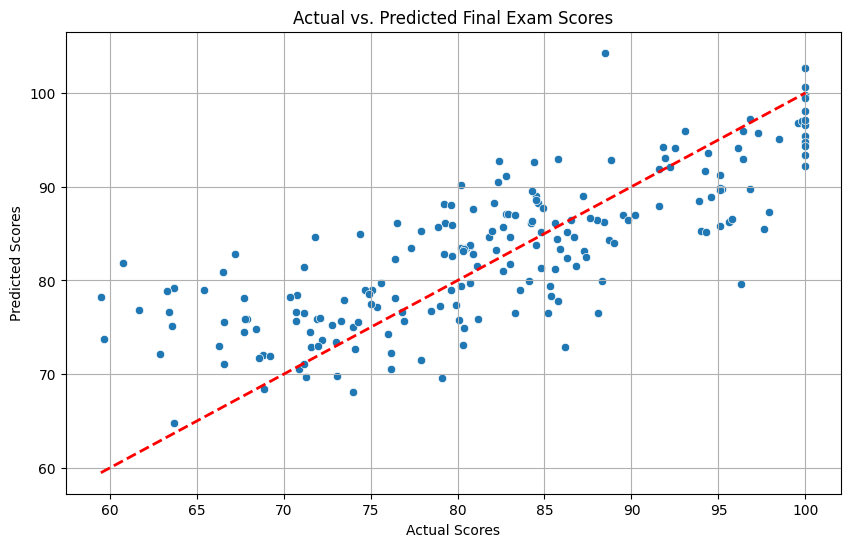

In [ ]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x='Actual', y='Predicted', data=comparison)
plt.title('Actual vs. Predicted Final Exam Scores')
plt.xlabel('Actual Scores')
plt.ylabel('Predicted Scores')
plt.grid(True)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], '--r', linewidth=2)
plt.show()

In [ ]:

X_single = df[['previous_grade']]
y = df['final_exam_score']

X_single_train, X_single_test, y_train, y_test = train_test_split(X_single, y, test_size=0.2, random_state=42)

single_model = LinearRegression()
single_model.fit(X_single_train, y_train)

y_single_pred = single_model.predict(X_single_test)
single_comparison = pd.DataFrame({'Actual': y_test, 'Predicted': y_single_pred})

single_mse = mean_squared_error(y_test, y_single_pred)
single_r2 = r2_score(y_test, y_single_pred)

print(f'Single Linear Regression - Mean Squared Error: {single_mse:.2f}')
print(f'Single Linear Regression - R-squared: {single_r2:.2f}')


Single Linear Regression - Mean Squared Error: 89.47
Single Linear Regression - R-squared: 0.17


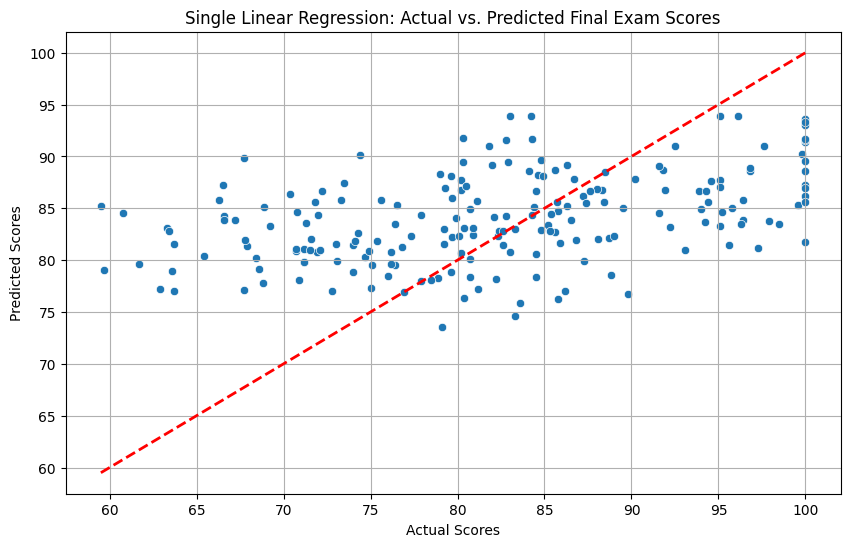

In [ ]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x='Actual', y='Predicted', data=single_comparison)
plt.title('Single Linear Regression: Actual vs. Predicted Final Exam Scores')
plt.xlabel('Actual Scores')
plt.ylabel('Predicted Scores')
plt.grid(True)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], '--r', linewidth=2)
plt.show()